##### 2-1. 합성데이터 생성
<pre style="font-size:16px">
# colab -> Colab CPU -> terminal
wget https://raw.githubusercontent.com/code-archive-git/ai/refs/heads/main/production/data/supplier_lots.csv
</pre>

#### 2-2. [1단계] 지표 정의 · 정규화

In [2]:
import pandas as pd

# 데이터를 불러오고...
lots = pd.read_csv('/content/data/supplier_lots.csv')

# supplier 별로 묶어서 다음의 집계를 실행 한다.(지표를 구하기 위한 기본값 생성)
g = lots.groupby('supplier').agg(
    lots=('n_insp', 'size'), # 총 로트(건)수
    insp=('n_insp', 'sum'), # IQC 검사 수
    ng=('n_ng', 'sum'), # IQC 불량 수
    late_lots=('delay_days', lambda s: (s > 0).sum()), # 지연 로트(건)수 (0보다 크냐? True|False)
    avg_delay=('delay_days', 'mean'), # 지연 일수 평균
    line_ng=('line_defect', 'sum'), # 투입 후 불량 로트 수
    price_idx=('price_idx', 'first') # 해당 협력사의 단가 지수 대표값
)
g.head()


,lots,insp,ng,late_lots,avg_delay,line_ng,price_idx
supplier,,,,,,,
S01,119,5950,297,3,0.075630,9,87.154016
S02,65,3250,267,4,0.153846,9,114.497841
S03,44,2200,121,1,0.022727,3,95.178731
S04,37,1850,46,3,0.243243,2,87.682726
S05,34,1700,79,2,0.235294,2,104.950738


In [3]:
# 베이지안 평활화 : 사전 강도 m (가상의 샘플 수)
# 불량률을 계산한다고 가정
#  k: IQC 불량 수, n : IQC 검사 수
def smooth(k, n, m):
    prior = k.sum() / n.sum() # 평균 불량률 = 총 불량 수 / 총 검사 수
    # 여기에 샘플위 수에 따라 보정이 들어간다.(베이지안 평활화 공식)
    # 보정률 = (불량 수 + a) ÷ (검사 수 + a + b)
    # a : 가상의 불량 건수 = 평균 불량률 * 샘플 수 -> 가상(대략)의 불량률 
    # b : 가상의 정상 건수 = (1-평균 불량률) * 샘플 수 -> 가상(대략)의 정상률 
    return (k + prior * m) / (n + m)

In [4]:
g['iqc_ng_rate']   = smooth(g['ng'], g['insp'], m=500) # IQC 불량 수 ÷ IQC 검사 수
g['late_rate']     = smooth(g['late_lots'], g['lots'], m=20) # 지연 로트 수 ÷ 총 로트 수
g['line_ng_rate']  = smooth(g['line_ng'], g['lots'], m=20) # 투입 후 불량 로트 수 ÷ 총 로트 수

INDICATORS = ['iqc_ng_rate', 'late_rate', 'avg_delay', 'line_ng_rate']

# Min-Max 정규화 (모두 '높을수록 위험' 이므로 방향 반전 불필요)
norm = (g[INDICATORS] - g[INDICATORS].min()) / (g[INDICATORS].max() - g[INDICATORS].min())
norm.head()

,iqc_ng_rate,late_rate,avg_delay,line_ng_rate
supplier,,,,
S01,0.414782,0.000000,0.082418,0.325394
S02,0.720312,0.163872,0.167653,0.623262
S03,0.459546,0.063843,0.024767,0.289327
S04,0.198181,0.251118,0.265073,0.232907
S05,0.384831,0.191379,0.256410,0.253816


#### 2-3. [2단계] 가중치 설계

In [5]:
import numpy as np

# IQC 불량률, 납기 지연율, 평균 지연일, 라인 불량로트율
A = np.array([[1,   2,   3,   1/2],
              [1/2, 1,   2,   1/3],
              [1/3, 1/2, 1,   1/4],
              [2,   3,   4,   1  ]])

# 행렬 A의 고윳값(val)과 고유벡터(vec)
val, vec = np.linalg.eig(A)
# 갯수가 4개이니 4와 가까워야 함 
print(f'고유벡터 : {vec}')
print(f'고윳값 : {val}')

고유벡터 : [[ 4.82560099e-01+0.j         -3.59827949e-04+0.42682741j
  -3.59827949e-04-0.42682741j  5.93397600e-01+0.j        ]
 [ 2.78707503e-01+0.j         -2.49793564e-01+0.04987579j
  -2.49793564e-01-0.04987579j -3.59216169e-01+0.j        ]
 [ 1.66148357e-01+0.j         -2.51701838e-02-0.17580881j
  -2.51701838e-02+0.17580881j  1.53510613e-01+0.j        ]
 [ 8.13543239e-01+0.j          8.49347712e-01+0.j
   8.49347712e-01-0.j         -7.03759564e-01+0.j        ]]
고윳값 : [ 4.03098350e+00+0.j         -1.68761514e-03+0.35326752j
 -1.68761514e-03-0.35326752j -2.76082680e-02+0.j        ]


In [6]:
# 벡터의 모든 층의 가장 큰 값이 있는 인덱스 값을 가져와서
w = np.real(vec[:, val.real.argmax()]) 
w /= w.sum() # 개별 값/w의 총합
# CR = (고윳값-n)/(n-1)/무작위지수(n=4 일 때 RI = 0.90)
CR = ((val.real.max() - 4) / 3) / 0.90
weights = dict(zip(INDICATORS,w.round(3)))

print('가중치 :', weights)
print('CR :', round(CR, 3))

가중치 : {'iqc_ng_rate': np.float64(0.277), 'late_rate': np.float64(0.16), 'avg_delay': np.float64(0.095), 'line_ng_rate': np.float64(0.467)}
CR : 0.011


#### 2-4. [3단계] 리스크 스코어 산출

In [7]:
# 1. 기준 리스크 점수(g['risk_score']) 계산
rand = np.random.default_rng(0) # 난수 생성기
w_vec = np.array([weights[c] for c in INDICATORS]) # 항목별 가중치 가져오기
print(INDICATORS)
print(w_vec)

# 점수 정규화 된 데이터 프레임을 가져와 해당 가중치 값 행렬곱(@) 후 100점 만점 점수로 변경 하여 저장
# 행렬곱? 가중치 값을 각 row 의 INDICATORS 들의 값과 곱한 후 더하는 연산
g['risk_score'] = (norm[INDICATORS].values @ w_vec) * 100
g.head()

['iqc_ng_rate', 'late_rate', 'avg_delay', 'line_ng_rate']
[0.277 0.16  0.095 0.467]


,lots,insp,ng,late_lots,avg_delay,line_ng,price_idx,iqc_ng_rate,late_rate,line_ng_rate,risk_score
supplier,,,,,,,,,,,
S01,119,5950,297,3,0.075630,9,87.154016,0.049878,0.038765,0.075072,27.468313
S02,65,3250,267,4,0.153846,9,114.497841,0.077790,0.075157,0.122765,53.273601
S03,44,2200,121,1,0.022727,3,95.178731,0.053967,0.052943,0.069297,27.497740
S04,37,1850,46,3,0.243243,2,87.682726,0.030090,0.094533,0.060264,22.902430
S05,34,1700,79,2,0.235294,2,104.950738,0.047142,0.081266,0.063612,28.011005


In [8]:

# 이 점수 가중치가 조금만 바뀌어도 흔들리는거 아냐?
# 민감도 분석을 통해 가중치를 약간(±20%) 흔들어 보자(약 1000 번)
base_rank = g['risk_score'].rank(ascending=False) # 먼저 가중치 큰 녀석 기준으로 순위를 먹여라
# base_rank # 정렬이 아니기에 변화가 없어보인다.
# 1등~5등 순서로 순위만 보기
print(base_rank.sort_values().head())

supplier
S09    1.0
S13    2.0
S02    3.0
S21    4.0
S29    5.0
Name: risk_score, dtype: float64


In [9]:
# 두 순위 목록이 얼마나 비슷하게 움직이는지 재는 스피어만 순위 상관계수(spearmanr) 함수
from scipy.stats import spearmanr 
# 1000번 반복하면서 나올 순위 상관계수(corrs)와 최상위 5개 유지 비율(top5_keep)
corrs, top5_keep = [], []
for _ in range(1000):# 1000번 실행
    # 이전에 만든 가중치 w_vec의 각 항목에 0.8~1.2 사이(±20%)의 무작위 배율을 n개 뽑아냄
    random_rate = rand.uniform(0.8, 1.2, len(w_vec))
    # 그리고 그 배율을 가중치에 곱해서 가중치에 변화를 줌
    w_p = w_vec * random_rate 
    w_p /= w_p.sum() # 이 값을 정규화 해 준다.(현재값/전체합계)
    # 이제 변경된 가중치로 다시 행렬곱 하여 점수를 낸다.
    s = norm[INDICATORS].values @ w_p
    # 새로운 시리즈를 만들어 랭킹을 다시 만들고
    r = pd.Series(s, index=g.index).rank(ascending=False)
    # 기준 순위와 변경된 순위 사이의 스피어만 상관계수를 구해 corrs 리스트에 추가(1에 가까울수록 순위 변동이 적다)
    corrs.append(spearmanr(base_rank, r).correlation)

    # 기존의 1~5등과 새로운 랭킹 에서 1~5등을 교집합(&) 하여 갯수를 센다
    # 왜? 겹치는게 많다는건 TOP% 내에서 순위가 유지되는 비율이 높다는 것
    keep_cnt = len(set(base_rank.nsmallest(5).index) & set(r.nsmallest(5).index))
    # 이걸 비율로 표시하기 위해 총 순위 갯수이 5와 나누어 추가
    top5_keep.append(keep_cnt/5)

# 이렇게 구한 내용을 출력
print(f'순위 상관 평균 {np.mean(corrs):.3f}, Top5 유지율 {np.mean(top5_keep):.0%}')

순위 상관 평균 0.996, Top5 유지율 93%


#### 2-5. [4단계] 취약 협력사 랭킹 · 등급화

In [10]:
import matplotlib.pyplot as plt
# cut 방식으로 진행
bins   = [-0.1, 30, 50, 70, 100]
labels = ['A(양호)', 'B(관찰)', 'C(주의)', 'D(고위험)']
# 등급지정
g['grade'] = pd.cut(g['risk_score'], bins=bins, labels=labels)

# 리스크 점수가 큰 순으로 정렬하고, 필요한 지표만 추려낸다.
ranking = g.sort_values('risk_score', ascending=False)[
    ['risk_score', 'grade', 'iqc_ng_rate', 'late_rate', 'avg_delay', 'line_ng_rate', 'lots']]
# 리스크가 큰 협력사 등급표(오름차순이라면 반대가 되겠지?)
ranking.head(10).round(3)    

,risk_score,grade,iqc_ng_rate,late_rate,avg_delay,line_ng_rate,lots
supplier,,,,,,,
S09,76.257,D(고위험),0.103,0.050,0.102,0.183,108
S13,64.173,C(주의),0.081,0.125,0.405,0.136,79
S02,53.274,C(주의),0.078,0.075,0.154,0.123,65
S21,49.364,B(관찰),0.054,0.261,0.918,0.061,85
S29,47.785,B(관찰),0.072,0.126,0.364,0.090,118
S26,46.450,B(관찰),0.050,0.234,0.848,0.065,33
S16,45.934,B(관찰),0.057,0.074,0.192,0.118,26
S18,44.477,B(관찰),0.055,0.104,0.311,0.104,61
S27,43.561,B(관찰),0.070,0.126,0.410,0.076,78


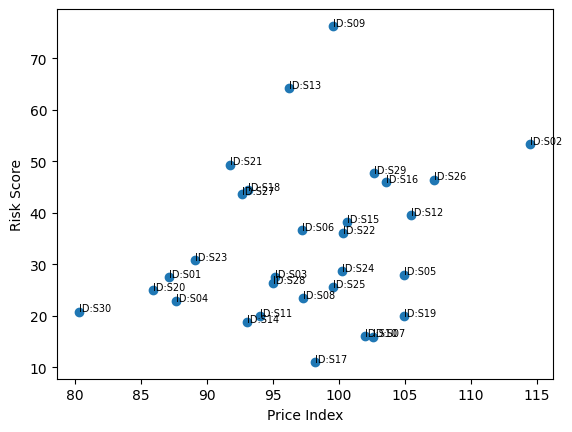

In [11]:
# 가격과 리스크 점수를 보여준다.
plt.scatter(g['price_idx'], g['risk_score'])
# supplier 당 row 를 꺼내서
for supplier, row in g.iterrows():
    # 특정 좌표에 supplier 명을 써 준다.
    plt.annotate(f'ID:{supplier}', (row['price_idx'], row['risk_score']), fontsize=7)
plt.xlabel('Price Index');
plt.ylabel('Risk Score')
plt.show()

<pre style="font-size:14px"></pre>

#### 2-6. [5단계] 집중관리 / 대체소싱 액션

In [24]:
# 등급별 조치 내용에 대해서 정의
ACTION = {
    'A(양호)'  : '무검사 확대 검토',
    'B(관찰)'  : '지표 모니터링 유지',
    'C(주의)'  : 'IQC 샘플 확대 + 개선계획서 요청',
    'D(고위험)': '품질 감사 + 대체소싱 검토',
}

DRIVER_KR = {
    'iqc_ng_rate':'불량률',
    'late_rate':'납기지연율',
    'avg_delay':'평균지연일',
    'line_ng_rate':'라인불량율'
}

In [22]:
# 선택사항 이지만 점수에 기여한 항목을 보여줌
def main_driver(row): # 협력사 row 를 받아서      
    contrib = {}
    for col in INDICATORS: # 지표를 하나씩 꺼내서
        # row 의 회사명,지표명 으로 값을 찾아 가중치와 곱해 넣습니다.
        # 지표:가중치 형태의 데이터 들이 저장됨
        contrib[col] = norm.loc[row.name, col] * weights[col]
    # print(contrib)

    # 그런 contrib 에서 지표 값으로 뽑아와 가장 큰 값을 찾아 내보냄
    return max(contrib, key=contrib.get) # 회사마다 가중치가 큰 지표명과 값이 반환 됨

In [25]:
# g : 지표
g['action'] = g['grade'].map(ACTION) # grade 를 하나씩 빼서 ACTION 에 대입 후 결과값을 담음
g['main_driver'] = g.apply(main_driver,axis=1).map(DRIVER_KR) # g 에서 row 방향으로 잘라서 main_driver 에게 전달
# 이걸 risk_score 기준으로 내림차순 이후, 필요한 컬럼만 선정, 10개를 뽑아낸다.
g.sort_values('risk_score', ascending=False)[['risk_score', 'grade', 'main_driver', 'action']].head(10)

,risk_score,grade,main_driver,action
supplier,,,,
S09,76.257314,D(고위험),라인불량율,품질 감사 + 대체소싱 검토
S13,64.173018,C(주의),라인불량율,IQC 샘플 확대 + 개선계획서 요청
S02,53.273601,C(주의),라인불량율,IQC 샘플 확대 + 개선계획서 요청
S21,49.363948,B(관찰),납기지연율,지표 모니터링 유지
S29,47.784943,B(관찰),라인불량율,지표 모니터링 유지
S26,46.450197,B(관찰),납기지연율,지표 모니터링 유지
S16,45.933785,B(관찰),라인불량율,지표 모니터링 유지
S18,44.476913,B(관찰),라인불량율,지표 모니터링 유지
S27,43.560648,B(관찰),불량률,지표 모니터링 유지
